# Highway Network Testing

In [4]:
%load_ext autoreload
%autoreload 2
# normally Python imports a file only once, the notebook will keep using the old version until you restart the kernel.

import torch
import math
from main import (get_dataloaders, Net, HighwayLayer, PlainConv,
                  run_experiment, evaluate, DATA_DIR, DEVICE, SEED)

# Data prep
train_loader, val_loader, test_loader = get_dataloaders(DATA_DIR)
print("sizes:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

images, labels = next(iter(train_loader))
print("batch:", tuple(images.shape), tuple(labels.shape))


# Testing the Highway layer
layer = HighwayLayer(channels=16)
x = torch.randn(8, 16, 32, 32)
y = layer(x)
print("in :", tuple(x.shape), "out:", tuple(y.shape))
print("gate mean at init:", torch.sigmoid(layer.gate(x)).mean().item())
print("params:", sum(p.numel() for p in layer.parameters()))
print()

sizes: 45000 5000 10000
batch: (128, 3, 32, 32) (128,)
in : (8, 16, 32, 32) out: (8, 16, 32, 32)
gate mean at init: 0.1319667100906372
params: 4640



### Random decisions

In [11]:
# Base line: 5,000 imgs, 10 classes, dataset is balanced = Random guessing accuracy = 1/10 = 0.1
print("baseline accuracy:", 1 / 10)

# The loss looks at the probability the model gives to the true class
# loss = −ln(p_true)
# p = (0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1)      # 10 classes, each 1/10
loss_base = - math.log(0.1)
print("baseline loss:", loss_base)
print()

baseline accuracy: 0.1
baseline loss: 2.3025850929940455



In [ ]:
print("=== Highway ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(HighwayLayer, layers_per_stage=3, conv_init=False)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=3, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

print("=== PlainConv ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=3, conv_init=False)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=3, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)

=== Highway ===

--- lr = 0.3 ---
epoch  1 | train loss 1.916 acc 0.266 | val loss 1.587 acc 0.376
epoch  2 | train loss 1.520 acc 0.439 | val loss 1.409 acc 0.477
epoch  3 | train loss 1.357 acc 0.510 | val loss 1.232 acc 0.551
best val acc: 0.5508

--- lr = 0.1 ---
epoch  1 | train loss 1.892 acc 0.277 | val loss 1.716 acc 0.333
epoch  2 | train loss 1.459 acc 0.461 | val loss 1.406 acc 0.494
epoch  3 | train loss 1.249 acc 0.549 | val loss 1.107 acc 0.611
best val acc: 0.611

--- lr = 0.03 ---
epoch  1 | train loss 2.050 acc 0.222 | val loss 1.752 acc 0.314
epoch  2 | train loss 1.683 acc 0.360 | val loss 1.571 acc 0.414
epoch  3 | train loss 1.485 acc 0.445 | val loss 1.433 acc 0.482
best val acc: 0.4824

--- lr = 0.01 ---
epoch  1 | train loss 2.196 acc 0.173 | val loss 2.029 acc 0.233
epoch  2 | train loss 1.932 acc 0.271 | val loss 1.752 acc 0.338
epoch  3 | train loss 1.724 acc 0.348 | val loss 1.667 acc 0.371
best val acc: 0.3706

--- lr = 0.003 ---
epoch  1 | train loss 2.298

Plain Conv doesn't learn at all, at any learning rate. Needs proper, better normalized initialization.


```py
# added in Net Class
for m in self.modules():
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
```

In [4]:
print("=== PlainConv ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=3, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=6, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)

=== PlainConv ===

--- lr = 0.3 ---
epoch  1 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  2 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  3 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  4 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  5 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  6 | train loss nan acc 0.100 | val loss nan acc 0.100
best val acc: 0.1

--- lr = 0.1 ---
epoch  1 | train loss 2.301 acc 0.110 | val loss 2.305 acc 0.100
epoch  2 | train loss 2.302 acc 0.104 | val loss 2.303 acc 0.100
epoch  3 | train loss 2.302 acc 0.104 | val loss 2.304 acc 0.100
epoch  4 | train loss 2.304 acc 0.097 | val loss 2.303 acc 0.100
epoch  5 | train loss 2.305 acc 0.100 | val loss 2.304 acc 0.100
epoch  6 | train loss 2.305 acc 0.098 | val loss 2.306 acc 0.100
best val acc: 0.1

--- lr = 0.03 ---
epoch  1 | train loss 2.097 acc 0.205 | val loss 1.859 acc 0.285
epoch  2 | train loss 1.752 acc 0.331 | val loss 1.653 acc 0.364
epoch

For `lr=0.3` and `lr=0.1` it was dead, but with lowering the learning rate we see it come alive.

In [5]:
print("=== Highway ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(HighwayLayer, layers_per_stage=3, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=6, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

=== Highway ===

--- lr = 0.3 ---
epoch  1 | train loss 1.845 acc 0.294 | val loss 1.531 acc 0.421
epoch  2 | train loss 1.490 acc 0.443 | val loss 1.422 acc 0.501
epoch  3 | train loss 1.351 acc 0.513 | val loss 1.282 acc 0.540
epoch  4 | train loss 1.234 acc 0.556 | val loss 1.105 acc 0.614
epoch  5 | train loss 1.172 acc 0.582 | val loss 1.131 acc 0.589
epoch  6 | train loss 1.128 acc 0.604 | val loss 1.041 acc 0.642
best val acc: 0.642

--- lr = 0.1 ---
epoch  1 | train loss 1.831 acc 0.301 | val loss 1.452 acc 0.454
epoch  2 | train loss 1.414 acc 0.477 | val loss 1.234 acc 0.546
epoch  3 | train loss 1.191 acc 0.572 | val loss 1.154 acc 0.604
epoch  4 | train loss 1.052 acc 0.627 | val loss 1.047 acc 0.638
epoch  5 | train loss 0.940 acc 0.666 | val loss 0.976 acc 0.660
epoch  6 | train loss 0.851 acc 0.700 | val loss 0.780 acc 0.725
best val acc: 0.7246

--- lr = 0.03 ---
epoch  1 | train loss 1.860 acc 0.294 | val loss 1.599 acc 0.368
epoch  2 | train loss 1.494 acc 0.443 | val

As we can see the best learning rate is:
- PlainConv `lr=0.01`
- Highway `lr=0.1`

## More layers, Deeper

Net has 3 stages. Each stage has 1 plain conv (to change the channels) plus N layers of chosen type (Highway or PlainConv):


```bash
depth = 3 stems + 3 × N
```
| layers_per_stage (N) | depth (conv layers) |
|---:|---:|
| 1  | 3 + 3 = 6   |
| 3  | 3 + 9 = 12  |
| 6  | 3 + 18 = 21 |
| 10 | 3 + 30 = 33 |



In [7]:
import json

configs = [("highway", HighwayLayer, 0.1),
           ("plain",   PlainConv,    0.01)]

results = {}
for name, layer_type, lr in configs:
    
    for lps in [1, 3, 6, 10]:
        torch.manual_seed(SEED)               # same start for every run
        depth = 3 + 3 * lps
        print(f"\n=== {name} | layers_per_stage={lps} (depth {depth}) | lr={lr} ===")

        model = Net(layer_type, layers_per_stage=lps, conv_init=True)
        history, best_acc = run_experiment(model, train_loader, val_loader,
                                           epochs=10, lr=lr, momentum=0.9, device=DEVICE)
        print("best val acc:", best_acc)

        results[f"{name}_{lps}"] = {"name": name, "lps": lps, "depth": depth, "lr": lr,
                                    "best_acc": best_acc, "history": history}

        
        with open("depth_results.json", "w") as f:
            json.dump(results, f, indent=2)     # save after EVERY run



=== highway | layers_per_stage=1 (depth 6) | lr=0.1 ===
epoch  1 | train loss 1.736 acc 0.340 | val loss 1.528 acc 0.437
epoch  2 | train loss 1.326 acc 0.515 | val loss 1.256 acc 0.550
epoch  3 | train loss 1.140 acc 0.592 | val loss 1.093 acc 0.620
epoch  4 | train loss 1.019 acc 0.638 | val loss 1.057 acc 0.616
epoch  5 | train loss 0.901 acc 0.685 | val loss 0.962 acc 0.661
epoch  6 | train loss 0.837 acc 0.710 | val loss 0.884 acc 0.694
epoch  7 | train loss 0.782 acc 0.729 | val loss 0.735 acc 0.738
epoch  8 | train loss 0.731 acc 0.748 | val loss 0.728 acc 0.742
epoch  9 | train loss 0.702 acc 0.757 | val loss 0.617 acc 0.783
epoch 10 | train loss 0.661 acc 0.773 | val loss 0.641 acc 0.782
best val acc: 0.7832

=== highway | layers_per_stage=3 (depth 12) | lr=0.1 ===
epoch  1 | train loss 1.828 acc 0.303 | val loss 1.462 acc 0.448
epoch  2 | train loss 1.425 acc 0.475 | val loss 1.285 acc 0.522
epoch  3 | train loss 1.204 acc 0.567 | val loss 1.208 acc 0.581
epoch  4 | train lo

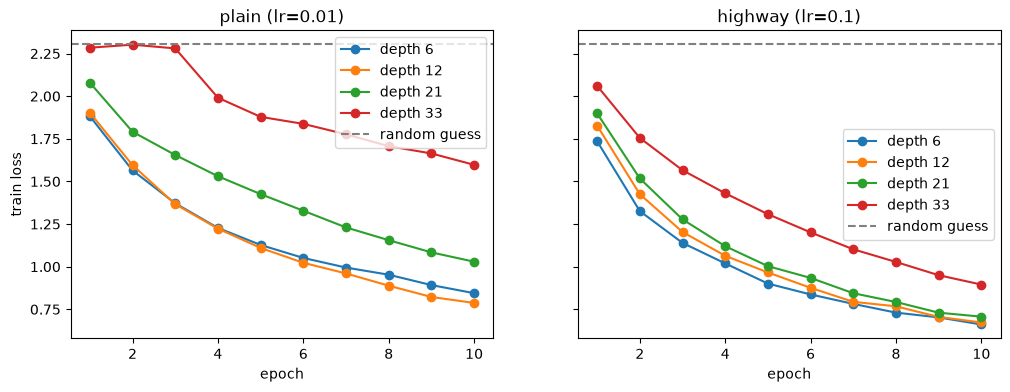

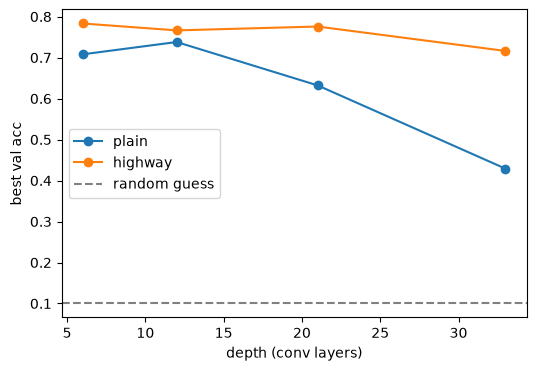

In [2]:
import json
import matplotlib.pyplot as plt

with open("depth_results.json") as f:
    results = json.load(f)

# Plot 1: training loss vs epoch, one line per depth (like the paper's Fig 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["plain", "highway"]):
    runs = [r for r in results.values() if r["name"] == name]
    for r in runs:
        epochs = range(1, len(r["history"]["train_loss"]) + 1)
        ax.plot(epochs, r["history"]["train_loss"], marker="o", label=f"depth {r['depth']}")
    ax.axhline(2.303, color="gray", linestyle="--", label="random guess")
    ax.set_title(f"{name} (lr={runs[0]['lr']})")
    ax.set_xlabel("epoch")
    ax.legend()

axes[0].set_ylabel("train loss")
plt.show()

# Plot 2: best val acc vs depth
plt.figure(figsize=(6, 4))
for name in ["plain", "highway"]:
    runs = sorted((r for r in results.values() if r["name"] == name), key=lambda r: r["depth"])
    plt.plot([r["depth"] for r in runs], [r["best_acc"] for r in runs], marker="o", label=name)
plt.axhline(0.1, color="gray", linestyle="--", label="random guess")
plt.xlabel("depth (conv layers)")
plt.ylabel("best val acc")
plt.legend()
plt.show()


Deep plain might do better at a smaller learning rate. Plain-33depth once at lr=0.003:

In [7]:
print("=== PlainConv-33 ===")
for lr in [0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=10, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=10, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

=== PlainConv-33 ===

--- lr = 0.003 ---
epoch  1 | train loss 2.228 acc 0.150 | val loss 2.086 acc 0.219
epoch  2 | train loss 1.947 acc 0.254 | val loss 1.887 acc 0.280
epoch  3 | train loss 1.808 acc 0.309 | val loss 1.717 acc 0.362
epoch  4 | train loss 1.708 acc 0.350 | val loss 1.674 acc 0.363
epoch  5 | train loss 1.600 acc 0.395 | val loss 1.587 acc 0.418
epoch  6 | train loss 1.520 acc 0.434 | val loss 1.373 acc 0.486
epoch  7 | train loss 1.435 acc 0.470 | val loss 1.393 acc 0.487
epoch  8 | train loss 1.346 acc 0.506 | val loss 1.231 acc 0.552
epoch  9 | train loss 1.296 acc 0.528 | val loss 1.225 acc 0.554
epoch 10 | train loss 1.236 acc 0.552 | val loss 1.229 acc 0.556
best val acc: 0.5562



plain needed re-tuning, highway didn't.

To train at 33 layers, the plain net needed a 3× smaller lr.

The highway net worked at depth 33 with the same lr it had at depth 12.

Highway nets don't need to be re-tuned as they get deeper.